<a href="https://colab.research.google.com/github/lovajujo/evolution-of-attacking-plays-in-women-s-football/blob/main/attacking_sequences.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ETL


## Import from Statsbomb

In [ ]:
!pip install statsbombpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [statsbombpy]


In [ ]:
from statsbombpy import sb

# get competiton id
comps = sb.competitions()
print(comps[comps["competition_international"] == True]
      .query("competition_gender == 'female'")
      [["competition_id", "season_id", "competition_name", "season_name", "competition_gender"]])

/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


    competition_id  season_id   competition_name season_name  \
76              53        315  UEFA Women's Euro        2025   
77              53        106  UEFA Women's Euro        2022   
78              72        107  Women's World Cup        2023   
79              72         30  Women's World Cup        2019   

   competition_gender  
76             female  
77             female  
78             female  
79             female  


In [ ]:
import pandas as pd

# get games
games_2019 = sb.matches(competition_id=72, season_id=30)
games_2023 = sb.matches(competition_id=72, season_id=107)
wwc_games = pd.concat([games_2019, games_2023], ignore_index=True)
print("games loaded: ", len(wwc_games))

/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(


games loaded:  116


In [ ]:


def get_attacking_sequences(match_id):

    events = sb.events(match_id=match_id)

    events = events.sort_values('index').copy()

    # Szekvenciák elkülönítése possession-ön belül
    group_cols = ['match_id', 'period', 'possession']

    events['sequence_no'] = (
        events.groupby(group_cols)['type']
        .transform(
            lambda x: x.eq('Shot').cumsum().shift(fill_value=0)
        )
    )

    # Egyedi szekvenciaazonosító
    events['sequence_id'] = (
        events['match_id'].astype(str) + '_' +
        events['period'].astype(str) + '_' +
        events['possession'].astype(str) + '_' +
        events['sequence_no'].astype(str)
    )

    # Releváns eseménytípusok
    events = events[
        events['type'].isin(['Pass', 'Carry', 'Dribble', 'Shot'])
    ].copy()

    grouped = events.groupby('sequence_id')
    valid_mask = (grouped.size() >= 2) & (grouped['type'].last() == 'Shot')
    valid_seq_ids = valid_mask[valid_mask].index

    sequences = events[events['sequence_id'].isin(valid_seq_ids)].copy()

    return sequences

all_sequences = []
match_ids = wwc_games['match_id'].unique().tolist()

for i, match_id in enumerate(match_ids):
    try:
        seq = get_attacking_sequences(match_id)
        if not seq.empty:
            all_sequences.append(seq)
    except Exception as e:
        print(f"Hiba a {match_id} meccsnél: {e}")

df_sequences = pd.concat(all_sequences, ignore_index=True)

/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: NoAuthWarning: credentials were not supplied. open data access only
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/statsbombpy/api_client.py:27: 

In [ ]:
columns_to_keep = [
    'sequence_id',
    'match_id',
    'index',
    'id',
    'possession',
    'type',
    'timestamp',
    'location',
    'pass_end_location',
    'carry_end_location',
    'duration',
    'pass_length',
    'pass_angle',
    'pass_height',
    'pass_cross',
    'pass_switch',
    'pass_through_ball'
    ]
df_sequences=df_sequences[columns_to_keep]

In [ ]:
print(f"szekvencia: {df_sequences['sequence_id'].nunique()}, "
      f"esemény: {len(df_sequences)}, lövés {len(df_sequences[df_sequences['type']=='Shot'])}")


szekvencia: 2690, esemény: 30087, lövés 2690


## Clean df

In [ ]:
df = df_sequences.drop_duplicates(subset=['id']).reset_index(drop=True)
df.head(5)

,sequence_id,match_id,index,id,possession,type,timestamp,location,pass_end_location,carry_end_location,duration,pass_length,pass_angle,pass_height,pass_cross,pass_switch,pass_through_ball
0,69284_1_10_0,69284,99,6680e6a5-44f3-4233-ba5e-8433829303d1,10,Pass,00:02:55.758,"[86.1, 32.9]","[93.5, 23.2]",NaN,0.981424,12.20041,-0.919099,Ground Pass,NaN,NaN,NaN
1,69284_1_10_0,69284,101,09d707ef-e3f1-486f-a594-4f0dc73b2b8f,10,Carry,00:02:56.739,"[93.5, 23.2]",NaN,"[98.4, 26.7]",2.648976,NaN,NaN,NaN,NaN,NaN,NaN
2,69284_1_10_0,69284,103,2ab161a3-ab43-4a6c-967f-876e5adb2e4f,10,Shot,00:02:59.388,"[98.4, 26.7]",NaN,NaN,1.292559,NaN,NaN,NaN,NaN,NaN,NaN
3,69284_1_30_0,69284,471,437aa30c-5702-4b7b-81cd-3c88cc7f11b4,30,Pass,00:12:27.631,"[39.2, 3.2]","[36.0, 9.2]",NaN,1.085326,6.80000,2.060754,Ground Pass,NaN,NaN,NaN
4,69284_1_30_0,69284,473,4c22670f-1446-466f-848c-4048d4373522,30,Carry,00:12:28.716,"[36.0, 9.2]",NaN,"[34.8, 13.5]",0.996974,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print(df.dtypes)
df.describe()

sequence_id            object
match_id                int64
index                   int64
id                     object
possession              int64
type                   object
timestamp              object
location               object
pass_end_location      object
carry_end_location     object
duration              float64
pass_length           float64
pass_angle            float64
pass_height            object
pass_cross             object
pass_switch            object
pass_through_ball      object
dtype: object


,match_id,index,possession,duration,pass_length,pass_angle
count,3.008700e+04,30087.000000,30087.000000,30087.000000,14157.000000,14157.000000
mean,2.128169e+06,1882.889354,101.938811,1.581483,20.745760,-0.012550
std,1.920013e+06,1033.541320,56.560635,1.312583,12.619829,1.552454
min,2.292100e+04,5.000000,2.000000,0.000000,0.400000,-3.137088
25%,2.298400e+04,1035.000000,55.000000,0.853363,11.600000,-1.259146
50%,3.893791e+06,1890.000000,101.000000,1.339500,17.555910,-0.047024
75%,3.893820e+06,2735.000000,147.000000,1.982744,26.947355,1.230269
max,3.906390e+06,4552.000000,285.000000,30.658410,94.271630,3.141593


In [ ]:
pass_missing = df[df['type'] == 'Pass'][['duration','pass_length', 'pass_angle', 'pass_height', 'pass_cross', 'pass_switch', 'pass_through_ball']].isna().sum()
carry_missing = df[df['type'] == 'Carry'][['duration','carry_end_location']].isna().sum()
general_missing = df[['type', 'timestamp', 'location']].isna().sum()
print("pass", pass_missing, "carry", carry_missing, "overall", general_missing)

pass duration                 0
pass_length              0
pass_angle               0
pass_height              0
pass_cross           13274
pass_switch          13700
pass_through_ball    14030
dtype: int64 carry duration              0
carry_end_location    0
dtype: int64 overall type         0
timestamp    0
location     0
dtype: int64


In [ ]:
bool_cols = ['pass_cross', 'pass_switch', 'pass_through_ball']
print(df[bool_cols].notna().sum())
df[bool_cols] = df[bool_cols].fillna(False)
df['timestamp'] = pd.to_timedelta(df['timestamp']).dt.total_seconds()

pass_cross           883
pass_switch          457
pass_through_ball    127
dtype: int64


/tmp/ipykernel_1695/799237903.py:3: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df[bool_cols] = df[bool_cols].fillna(False)


In [ ]:
import numpy as np
import pandas as pd
import ast

def parse_location(loc):
    if loc is None or (isinstance(loc, float) and pd.isna(loc)):
        return np.nan, np.nan
    if isinstance(loc, str):
        loc = ast.literal_eval(loc)
    if isinstance(loc, (list, tuple, np.ndarray)) and len(loc) >= 2:
        return loc[0], loc[1]
    return np.nan, np.nan

df['x'], df['y'] = zip(*df['location'].apply(parse_location))
df['pass_end_x'], df['pass_end_y'] = zip(*df['pass_end_location'].apply(parse_location))
df['carry_end_x'], df['carry_end_y'] = zip(*df['carry_end_location'].apply(parse_location))
df = df.drop(columns=['location', 'pass_end_location', 'carry_end_location'])

In [ ]:
cols = ['x', 'y', 'pass_end_x', 'pass_end_y', 'carry_end_x', 'carry_end_y']
min_max_df = df[cols].agg(['min', 'max'])
print(min_max_df)

         x     y  pass_end_x  pass_end_y  carry_end_x  carry_end_y
min    0.9   0.1         2.0         0.1          1.5          0.4
max  120.0  80.0       120.0        79.9        119.9         79.6


In [ ]:
df["pass_height_num"] = (df["pass_height"] == "High Pass").astype(int)

In [ ]:
magas_passz_arany = df["pass_height_num"].mean()
print(f"A magas passzok aránya: {magas_passz_arany:.2%}")

A magas passzok aránya: 10.54%


In [ ]:
# vertikalitás (1 előre, -1 hátra)
df['pass_angle_cos'] = np.cos(df['pass_angle'])
#horizontális (1 jobbra, -1 balra)
df['pass_angle_sin'] = np.sin(df['pass_angle'])

In [ ]:

def get_x_zone(x):
  if pd.isna(x):
    return np.nan
  if x < 40:
      return 'defensive'
  elif x < 80:
      return 'middle'
  return 'attacking'

def get_y_zone(y):
  if pd.isna(y):
    return np.nan
  if y < 26.67:
      return 'left'
  elif y > 53.33:
      return 'right'
  return 'center'



def get_pass_direction(angle):
  if pd.isna(angle):
    return np.nan
  if -np.pi / 6 <= angle <= np.pi / 6:
        return 'forward'
  elif np.abs(angle) >= 5 * np.pi / 6:
        return 'backward'
  return 'side'

In [ ]:
df['x_zone'] = df['x'].apply(get_x_zone)
df['y_zone'] = df['y'].apply(get_y_zone)
df['pass_direction'] = df['pass_angle'].apply(get_pass_direction)

In [ ]:
df.head()

,sequence_id,match_id,index,id,possession,type,timestamp,duration,pass_length,pass_angle,...,pass_end_x,pass_end_y,carry_end_x,carry_end_y,pass_height_num,pass_angle_cos,pass_angle_sin,x_zone,y_zone,pass_direction
0,69284_1_10_0,69284,99,6680e6a5-44f3-4233-ba5e-8433829303d1,10,Pass,175.758,0.981424,12.20041,-0.919099,...,93.5,23.2,NaN,NaN,0,0.606537,-0.795055,attacking,center,side
1,69284_1_10_0,69284,101,09d707ef-e3f1-486f-a594-4f0dc73b2b8f,10,Carry,176.739,2.648976,NaN,NaN,...,NaN,NaN,98.4,26.7,0,NaN,NaN,attacking,left,NaN
2,69284_1_10_0,69284,103,2ab161a3-ab43-4a6c-967f-876e5adb2e4f,10,Shot,179.388,1.292559,NaN,NaN,...,NaN,NaN,NaN,NaN,0,NaN,NaN,attacking,center,NaN
3,69284_1_30_0,69284,471,437aa30c-5702-4b7b-81cd-3c88cc7f11b4,30,Pass,747.631,1.085326,6.80000,2.060754,...,36.0,9.2,NaN,NaN,0,-0.470588,0.882353,defensive,left,side
4,69284_1_30_0,69284,473,4c22670f-1446-466f-848c-4048d4373522,30,Carry,748.716,0.996974,NaN,NaN,...,NaN,NaN,34.8,13.5,0,NaN,NaN,defensive,left,NaN


In [ ]:
df.describe()

,match_id,index,possession,timestamp,duration,pass_length,pass_angle,x,y,pass_end_x,pass_end_y,carry_end_x,carry_end_y,pass_height_num,pass_angle_cos,pass_angle_sin
count,3.008700e+04,30087.000000,30087.000000,30087.000000,30087.000000,14157.000000,14157.000000,30087.000000,30087.000000,14157.000000,14157.000000,12565.000000,12565.000000,30087.000000,14157.000000,14157.000000
mean,2.128169e+06,1882.889354,101.938811,1518.529414,1.581483,20.745760,-0.012550,73.560398,39.921072,75.799958,39.672141,73.598241,39.761369,0.105428,0.206093,-0.014797
std,1.920013e+06,1033.541320,56.560635,874.882601,1.312583,12.619829,1.552454,29.071175,22.366855,28.113971,21.247141,27.945193,21.610155,0.307109,0.647409,0.733646
min,2.292100e+04,5.000000,2.000000,0.276000,0.000000,0.400000,-3.137088,0.900000,0.100000,2.000000,0.100000,1.500000,0.400000,0.000000,-1.000000,-1.000000
25%,2.298400e+04,1035.000000,55.000000,767.499500,0.853363,11.600000,-1.259146,51.800000,21.900000,54.200000,22.900000,52.500000,21.900000,0.000000,-0.281474,-0.768725
50%,3.893791e+06,1890.000000,101.000000,1512.488000,1.339500,17.555910,-0.047024,77.700000,39.800000,79.900000,39.600000,77.800000,39.600000,0.000000,0.318847,-0.037012
75%,3.893820e+06,2735.000000,147.000000,2267.590500,1.982744,26.947355,1.230269,97.700000,58.200000,100.000000,56.700000,96.700000,57.700000,0.000000,0.820051,0.752922
max,3.906390e+06,4552.000000,285.000000,3479.471000,30.658410,94.271630,3.141593,120.000000,80.000000,120.000000,79.900000,119.900000,79.600000,1.000000,1.000000,1.000000


In [ ]:

df.to_csv('attacking_sequences.csv', index=False)

# Load from dirve

In [2]:
from google.colab import drive
import pandas as pd
drive.mount('/content/drive')
path='/content/drive/Othercomputers/Saját laptop/Jujo/tf elemzes msc/3/szakdoga/attacking_sequences.csv'
df = pd.read_csv(path)
df.head()

Mounted at /content/drive


,duration,id,index,match_id,pass_angle,pass_cross,pass_height,pass_length,pass_shot_assist,pass_switch,...,pass_end_x,pass_end_y,carry_end_x,carry_end_y,pass_height_num,pass_angle_cos,pass_angle_sin,x_zone,y_zone,pass_direction
0,0.981424,6680e6a5-44f3-4233-ba5e-8433829303d1,99,69284,-0.919099,False,Ground Pass,12.20041,True,False,...,93.5,23.2,NaN,NaN,0,0.606537,-0.795055,attacking,center,side
1,2.648976,09d707ef-e3f1-486f-a594-4f0dc73b2b8f,101,69284,NaN,False,NaN,NaN,False,False,...,NaN,NaN,98.4,26.7,0,NaN,NaN,attacking,left,NaN
2,1.292559,2ab161a3-ab43-4a6c-967f-876e5adb2e4f,103,69284,NaN,False,NaN,NaN,False,False,...,NaN,NaN,NaN,NaN,0,NaN,NaN,attacking,center,NaN
3,1.085326,437aa30c-5702-4b7b-81cd-3c88cc7f11b4,471,69284,2.060754,False,Ground Pass,6.80000,False,False,...,36.0,9.2,NaN,NaN,0,-0.470588,0.882353,defensive,left,side
4,0.996974,4c22670f-1446-466f-848c-4048d4373522,473,69284,NaN,False,NaN,NaN,False,False,...,NaN,NaN,34.8,13.5,0,NaN,NaN,defensive,left,NaN


# PCA - passes

In [ ]:
passes = df[df["type"] == "Pass"][["x", "y", "pass_length", "pass_angle_sin","pass_angle_cos", "pass_height_num"]].copy()
passes.head()

,x,y,pass_length,pass_angle_sin,pass_angle_cos,pass_height_num
0,86.1,32.9,12.200410,-0.795055,0.606537,0
3,39.2,3.2,6.800000,0.882353,-0.470588,0
5,34.8,13.5,6.300794,0.587228,0.809422,0
6,38.8,31.1,3.252691,-0.707107,0.707107,1
10,93.8,40.8,17.700283,0.604510,0.796597,0


In [ ]:
passes.shape


(13789, 6)

In [ ]:
print(passes.isna().sum())

x                  0
y                  0
pass_length        0
pass_angle_sin     0
pass_angle_cos     0
pass_height_num    0
dtype: int64


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

passes_scaled = scaler.fit_transform(passes)
passes_scaled = pd.DataFrame(passes_scaled, columns=passes.columns)
passes_scaled.head()

,x,y,pass_length,pass_angle_sin,pass_angle_cos,pass_height_num
0,0.603001,-0.300234,-0.651541,-1.078606,0.605881,-0.713308
1,-1.028317,-1.557038,-1.089270,1.226611,-1.044767,-0.713308
2,-1.181362,-1.121177,-1.129733,0.821028,0.916794,-0.713308
3,-1.042230,-0.376404,-1.376797,-0.957741,0.760000,1.401919
4,0.870829,0.034068,-0.205749,0.844779,0.897141,-0.713308


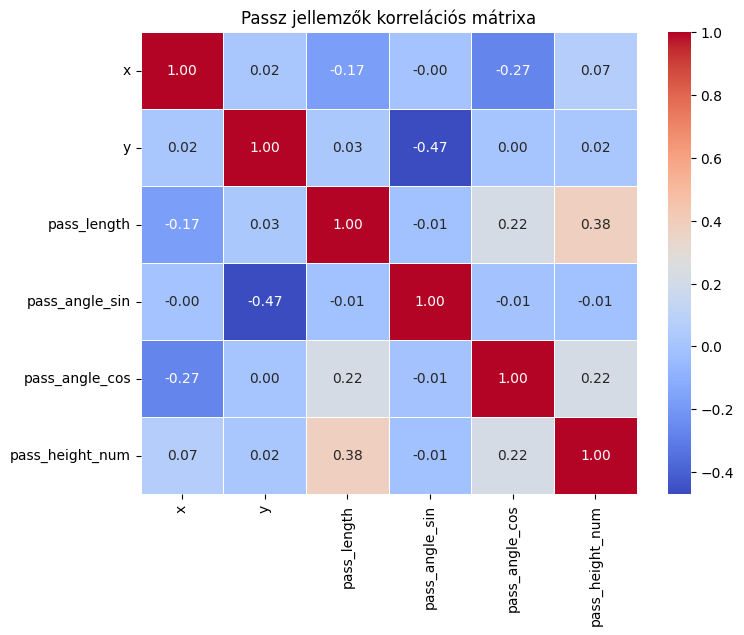

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = passes_scaled.corr()

# Ábrázolás hőtérképpel
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Passz jellemzők korrelációs mátrixa")
plt.show()

### Assumption check

In [ ]:
!pip install factor_analyzer

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor_analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42656 sha256=3cea8e29c89adc0ed8b6489bb9491afd167c5946b3311ffbd27d0e5590293f63
  Stored in directory: /root/.cache/pip/wheels/87/6e/8f/914f20e0242ee0214e5c8336031a2fab12e632e4695fbb7276
Successfully built factor_analyzer


In [ ]:
from factor_analyzer.factor_analyzer import calculate_kmo, calculate_bartlett_sphericity

X = passes_scaled

# KMO-teszt
kmo_all, kmo_model = calculate_kmo(X)

print("KMO érték:", kmo_model)

# Bartlett-teszt
chi_square_value, p_value = calculate_bartlett_sphericity(X)

print("Bartlett chi-square:", chi_square_value)
print("Bartlett p-value:", p_value)

KMO érték: 0.5070775044906269
Bartlett chi-square: 10728.152239312958
Bartlett p-value: 0.0


In [ ]:
kmo_all, kmo_model = calculate_kmo(X)

kmo_results = pd.DataFrame({
    'Variable': X.columns,
    'KMO': kmo_all
})

print(kmo_results.sort_values('KMO'))

          Variable       KMO
0                x  0.398964
5  pass_height_num  0.489499
3   pass_angle_sin  0.500707
1                y  0.501196
2      pass_length  0.529549
4   pass_angle_cos  0.613169


In [ ]:
X2 = X.drop(columns=['x'])

kmo_all, kmo_model = calculate_kmo(X2)

print("Új KMO:", kmo_model)

kmo_results = pd.DataFrame({
    'Variable': X2.columns,
    'KMO': kmo_all
})

print(kmo_results.sort_values('KMO'))

Új KMO: 0.5447321715695194
          Variable       KMO
2   pass_angle_sin  0.500702
0                y  0.501273
4  pass_height_num  0.552714
1      pass_length  0.553611
3   pass_angle_cos  0.750785


# Aggreagate sequences

In [ ]:
import numpy as np
import pandas as pd
import math

grouped = df.groupby('sequence_id')
# Egyedi aggregációk kiszámítása
attacks_list = []

for sequence_id, group in grouped:
    group = group.sort_values('index')

    #volumen

    total_duration = group['duration'].sum()

    total_events = len(group)

    #passes

    passes_in_group = group[group['type'] == 'Pass']

    pass_count=len(passes_in_group)

    total_pass_length = passes_in_group['pass_length'].sum()

    mean_pass_length = passes_in_group['pass_length'].mean() if not passes_in_group.empty else 0.0

    pass_length_std = passes_in_group['pass_length'].std() if len(passes_in_group) > 1 else 0.0

    long_passes=(passes_in_group['pass_length']>=35).sum()
    long_pass_ratio=long_passes/pass_count if pass_count>0 else 0.0

    cross_count = group['pass_cross'].sum()

    switch_count = group['pass_switch'].sum()

    pass_height_sum = group['pass_height_num'].sum()
    high_pass_ratio=pass_height_sum/pass_count if pass_count >0 else 0.0

    through_ball_count = group['pass_through_ball'].sum()

    direction_counts = passes_in_group['pass_direction'].value_counts()
    forward_pass_ratio=direction_counts.get('forward', 0)/pass_count if pass_count >0 else 0.0
    side_pass_ratio=direction_counts.get('side', 0)/pass_count if pass_count >0 else 0.0
    backward_pass_ratio=(1 - (forward_pass_ratio + side_pass_ratio))

    dribble_count = len(group[group['type'] == 'Dribble'])

    #spatial

    y_coords = pd.concat([group['y'], group['pass_end_y'], group['carry_end_y']]).dropna()
    width = (y_coords.max() - y_coords.min()) if not y_coords.empty else 0.0

    start_x = group['x'].iloc[0]

    start_y = group['y'].iloc[0]

    start_y_unilat=abs(start_y-40)

    shot_x=group['x'].iloc[-1]

    shot_y=group['y'].iloc[-1]

    shot_y_unilat=abs(shot_y-40)

    d3_duration_ratio= (group[group['x_zone'] == 'defensive']['duration'].sum())/total_duration
    m3_duration_ratio= (group[group['x_zone'] == 'middle']['duration'].sum())/total_duration
    a3_duration_ratio=(1-(d3_duration_ratio + m3_duration_ratio))

    r_duration_ratio=(group[group['y_zone'] == 'rigth']['duration'].sum())/total_duration
    l_duration_ratio=(group[group['y_zone'] == 'left']['duration'].sum())/total_duration
    c_duration_ratio=(1-(r_duration_ratio + l_duration_ratio))

    #distance

    coords = list(zip(group['x'], group['y']))
    total_distance = sum(math.dist(coords[i], coords[i+1]) for i in range(len(coords) - 1))

    net_distance = math.dist((start_x, start_y), (shot_x, shot_y))

    carries = group[group['type'] == 'Carry']
    if not carries.empty:
      carries = carries.copy()
      carries['carry_dist'] = np.hypot(carries['carry_end_x'] - carries['x'], carries['carry_end_y'] - carries['y'])
      carry_distance = carries['carry_dist'].sum(skipna=True)
    else:
      carry_distance = 0.0
    carry_distance_ratio = carry_distance / total_distance if total_distance > 0 else 0.0

    #dynamics

    directness=net_distance/total_distance

    tempo=total_events/total_duration

    attack = {
        'sequence_id': sequence_id,
        #volumen
        'total_duration': total_duration,
        'total_events':total_events,
        # passes
        ## height
        'high_pass_%': high_pass_ratio,
        ## direction
        'forward_pass_%': forward_pass_ratio,
        'side_pass_%': side_pass_ratio,
        'backward_pass_%': backward_pass_ratio,
        ## length
        'pass_length_mean': mean_pass_length,
        'pass_length_std': pass_length_std,
        'long_pass_%': long_pass_ratio,

        # spare events - special passes
        'cross_count': cross_count,
        'switch_count': switch_count,
        'through_ball_count': through_ball_count,
        'dribble_ratio': dribble_count/total_events,

        # spatial

        'start_x': start_x,
        'start_y': start_y,
        'start_y_unilat': start_y_unilat,
        'shot_x': shot_x,
        'shot_y':shot_y,
        'shot_y_unilat' : shot_y_unilat,
        'shot_distance': net_distance,
        'total_distance': total_distance,

        'width': width,
        'd3_time_%': d3_duration_ratio,
        'm3_time_%':m3_duration_ratio,
        'a3_time_%':a3_duration_ratio,
        'left_time_%': l_duration_ratio,
        'right_time_%': r_duration_ratio,
        'side_time_%' : 1-c_duration_ratio,
        'central_time_%': c_duration_ratio,
        #dynamics
        'directness': directness,
        'tempo': tempo,
        'carry_distance_ratio': carry_distance_ratio
    }

    attacks_list.append(attack)


attacks = pd.DataFrame(attacks_list)


print(f"Az attacks tábla elkészült zóna- és passzirány-számlálókkal. Sorok száma: {len(attacks)}")
attacks.head()

Az attacks tábla elkészült zóna- és passzirány-számlálókkal. Sorok száma: 2690


,sequence_id,total_duration,total_events,high_pass_%,forward_pass_%,side_pass_%,backward_pass_%,pass_length_mean,pass_length_std,long_pass_%,cross_count,switch_count,through_ball_count,dribble_ratio,start_x,start_y,start_y_unilat,shot_x,shot_y,shot_y_unilat,shot_distance,total_distance,width,d3_time_%,m3_time_%,a3_time_%,left_time_%,right_time_%,side_time_%,central_time_%,directness,tempo,carry_distance_ratio
0,22921_1_17_0,9.450070,9,0.0,0.50,0.5,0.00,8.427368,1.633796,0.00,0,0,0,0.0,61.9,16.8,23.2,101.0,40.7,0.7,45.825975,55.231634,24.2,0.0,0.394325,0.605675,0.703572,0.0,0.703572,0.296428,0.829705,0.952374,0.364375
1,22921_1_24_0,7.320604,4,0.0,0.50,0.5,0.00,13.514164,5.054177,0.00,1,0,0,0.0,87.7,71.0,31.0,112.1,43.8,3.8,36.540389,51.322707,32.1,0.0,0.000000,1.000000,0.000000,0.0,0.000000,1.000000,0.711973,0.546403,0.498751
2,22921_1_31_0,3.360700,3,1.0,0.00,1.0,0.00,25.460769,25.495066,0.50,0,1,0,0.0,120.0,80.0,40.0,97.1,50.9,10.9,37.029988,64.986644,43.0,0.0,0.000000,1.000000,0.000000,0.0,0.000000,1.000000,0.569809,0.892671,0.000000
3,22921_1_46_0,1.742400,2,1.0,0.00,1.0,0.00,36.863533,0.000000,1.00,0,0,0,0.0,120.0,80.0,40.0,95.7,50.1,10.1,38.529210,38.529210,36.6,0.0,0.000000,1.000000,0.000000,0.0,0.000000,1.000000,1.000000,1.147842,0.000000
4,22921_1_46_1,14.401026,7,0.5,0.25,0.5,0.25,28.640816,12.914521,0.25,1,0,0,0.0,84.3,30.7,9.3,109.7,42.9,2.9,28.178006,123.016789,29.8,0.0,0.491402,0.508598,0.137351,0.0,0.137351,0.862649,0.229058,0.486076,0.075940


In [ ]:
attacks.describe()

,total_duration,total_events,high_pass_%,forward_pass_%,side_pass_%,backward_pass_%,pass_length_mean,pass_length_std,long_pass_%,cross_count,switch_count,through_ball_count,dribble_ratio,start_x,start_y,start_y_unilat,shot_x,shot_y,shot_y_unilat,shot_distance,total_distance,width,d3_time_%,m3_time_%,a3_time_%,left_time_%,right_time_%,side_time_%,central_time_%,directness,tempo,carry_distance_ratio
count,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000,2690.0,2690.000000,2690.000000,2690.000000,2690.000000,2690.000000
mean,17.688504,11.184758,0.368613,0.191832,0.714440,0.093727,23.671899,8.509158,0.252127,0.328253,0.169888,0.047212,0.019557,72.064796,41.808513,26.134387,104.449442,39.934164,7.553420,51.808942,169.074850,44.792416,0.116137,0.283096,0.600768,0.311106,0.0,0.311106,0.688894,0.560376,0.725579,0.185788
std,18.076084,10.849235,0.374502,0.242945,0.291155,0.196973,10.981761,7.642670,0.350739,0.543104,0.405137,0.213877,0.047358,36.543868,29.679340,14.173037,8.511529,9.444938,5.668846,23.996787,174.860872,19.532150,0.184616,0.275866,0.343382,0.308854,0.0,0.308854,0.308854,0.330714,0.305781,0.197918
min,0.423239,2.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.200000,0.100000,0.000000,61.400000,9.500000,0.000000,0.300000,0.300000,0.000000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.018123,0.142513,0.000000
25%,4.572163,3.000000,0.000000,0.000000,0.500000,0.000000,16.962599,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,43.600000,12.300000,13.325000,98.700000,33.500000,2.800000,36.401683,47.336398,31.400000,0.000000,0.000000,0.288665,0.000000,0.0,0.000000,0.453648,0.240412,0.562720,0.044914
50%,12.205746,8.000000,0.250000,0.125000,0.750000,0.000000,21.276231,8.402943,0.095238,0.000000,0.000000,0.000000,0.000000,73.650000,41.700000,30.200000,106.100000,40.000000,6.300000,47.125044,105.734560,43.550000,0.000000,0.263963,0.558692,0.256697,0.0,0.256697,0.743303,0.536806,0.667293,0.147740
75%,23.821108,15.000000,0.600000,0.333333,1.000000,0.125000,29.444282,12.878250,0.333333,1.000000,0.000000,0.000000,0.000000,106.400000,72.975000,39.900000,111.100000,46.200000,11.500000,66.123501,230.418751,60.900000,0.198439,0.502926,1.000000,0.546352,0.0,0.546352,1.000000,0.914867,0.805045,0.249685
max,196.912904,132.000000,1.000000,1.000000,1.000000,1.000000,80.624810,52.418496,1.000000,4.000000,4.000000,2.000000,0.333333,120.000000,80.000000,40.000000,119.600000,79.400000,39.400000,117.275104,1656.819662,79.200000,0.933278,1.000000,1.000000,1.000000,0.0,1.000000,1.000000,1.000000,4.725462,1.000000


In [ ]:
pd.set_option('display.max_columns', None)

In [ ]:
# @title
longest=wwc_games[wwc_games["match_id"]==3893822]
longest
#spanyoloknak 68% volt a possession, mégis 4-0ra sz

,match_id,match_date,kick_off,home_score,away_score,match_status,match_status_360,last_updated,last_updated_360,match_week,competition_id,competition_country_name,competition_name,competition,season_id,season,home_team_id,home_team,home_team_gender,home_team_group,home_team_country_id,home_team_country_name,away_team_id,away_team,away_team_gender,away_team_group,away_team_country_id,away_team_country_name,competition_stage_id,competition_stage,stadium_id,stadium,stadium_country_id,stadium_country_name,referee_id,referee,referee_country_id,referee_country_name,home_managers,away_managers,home_manager_id,home_manager_name,home_manager_nickname,home_manager_dob,home_manager_country_id,home_manager_country_name,away_manager_id,away_manager_name,away_manager_nickname,away_manager_dob,away_manager_country_id,away_manager_country_name,data_version,shot_fidelity_version,xy_fidelity_version
97,3893822,2023-07-31,07:00:00.000,4,0,available,available,2026-05-03T13:49:41.352078,2026-05-03T13:55:33.041563,3,72,International,Women's World Cup,International - Women's World Cup,107,2023,1210,Japan Women's,female,None,114,Japan,863,Spain Women's,female,None,214,Spain,10,Group Stage,98115,Wellington Regional Stadium,14,Australia,751.0,Katja Koroleva,241.0,United States of America,Futoshi Ikeda,Jorge Vilda,1003258,Futoshi Ikeda,None,1970-10-04,114,Japan,418,Jorge Vilda,None,1981-07-07,214,Spain,1.1.0,2,2


In [ ]:
attacks.columns

Index(['sequence_id', 'total_duration', 'total_events', 'high_pass_%',
       'forward_pass_%', 'side_pass_%', 'backward_pass_%', 'pass_length_mean',
       'pass_length_std', 'long_pass_%', 'cross_count', 'switch_count',
       'through_ball_count', 'dribble_ratio', 'start_x', 'start_y',
       'start_y_unilat', 'shot_x', 'shot_y', 'shot_y_unilat', 'shot_distance',
       'total_distance', 'width', 'd3_time_%', 'm3_time_%', 'a3_time_%',
       'left_time_%', 'right_time_%', 'side_time_%', 'central_time_%',
       'directness', 'tempo', 'carry_distance_ratio'],
      dtype='object')

In [ ]:
#attacks_3=attacks[attacks["total_events"]>2].copy()
cols_keep=[ #'sequence_id',
            'total_duration', #'total_events',
            'high_pass_%',
            'forward_pass_%', 'side_pass_%', #'backward_pass_%',
            #'pass_length_mean','pass_length_std',
            'long_pass_%', 'cross_count',
            #'switch_count','through_ball_count', 'dribble_ratio',
            'start_x', #'start_y',
            'start_y_unilat',
            'shot_x', #'shot_y',
            'shot_y_unilat',
            #'shot_distance',
            #'total_distance',
            'width',
            'd3_time_%', 'm3_time_%', #'a3_time_%',
            #'left_time_%', 'right_time_%',
            'side_time_%', #'central_time_%',
            'directness', 'tempo', 'carry_distance_ratio']
attacks_filtered = attacks[cols_keep]

In [ ]:
# @title
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import shapiro

# Feltételezve, hogy az adataid a 'df' nevű DataFrame-ben vannak
for column in attacks_filtered.columns:
    data = attacks_filtered[column].dropna()

    plt.figure(figsize=(6, 4))
    sns.histplot(data, kde=True, bins=30)
    plt.title(f'Hisztogram: {column}')
    plt.show()

    stat, p_value = shapiro(data)
    print(f'{column} | Shapiro-Wilk statisztika: {stat:.4f}, p-érték: {p_value:.5f}')

In [ ]:
from sklearn.preprocessing import RobustScaler


scaler = RobustScaler()

attacks_scaled = scaler.fit_transform(attacks_filtered)
attacks_scaled_df = pd.DataFrame(attacks_scaled, columns=attacks_filtered.columns)
attacks_scaled_df.head()

,total_duration,high_pass_%,forward_pass_%,side_pass_%,long_pass_%,cross_count,start_x,start_y_unilat,shot_x,shot_y_unilat,width,d3_time_%,m3_time_%,side_time_%,directness,tempo,carry_distance_ratio
0,-0.143160,-0.416667,1.125,-0.5,-0.285714,0.0,-0.187102,-0.263405,-0.411290,-0.643678,-0.655932,0.0,0.259207,0.817923,0.434275,1.176440,1.057940
1,-0.253788,-0.416667,1.125,-0.5,-0.285714,1.0,0.223726,0.030103,0.483871,-0.287356,-0.388136,0.0,-0.524855,-0.469839,0.259716,-0.498874,1.714169
2,-0.459508,1.250000,-0.375,0.5,1.214286,0.0,0.738057,0.368768,-0.725806,0.528736,-0.018644,0.0,-0.524855,-0.469839,0.048933,0.930066,-0.721487
3,-0.543580,1.250000,-0.375,0.5,2.714286,0.0,0.738057,0.368768,-0.838710,0.436782,-0.235593,0.0,-0.524855,-0.469839,0.686767,1.983076,-0.721487
4,0.114047,0.416667,0.375,-0.5,0.464286,1.0,0.169586,-0.786453,0.290323,-0.390805,-0.466102,0.0,0.452232,-0.218442,-0.456292,-0.747823,-0.350636


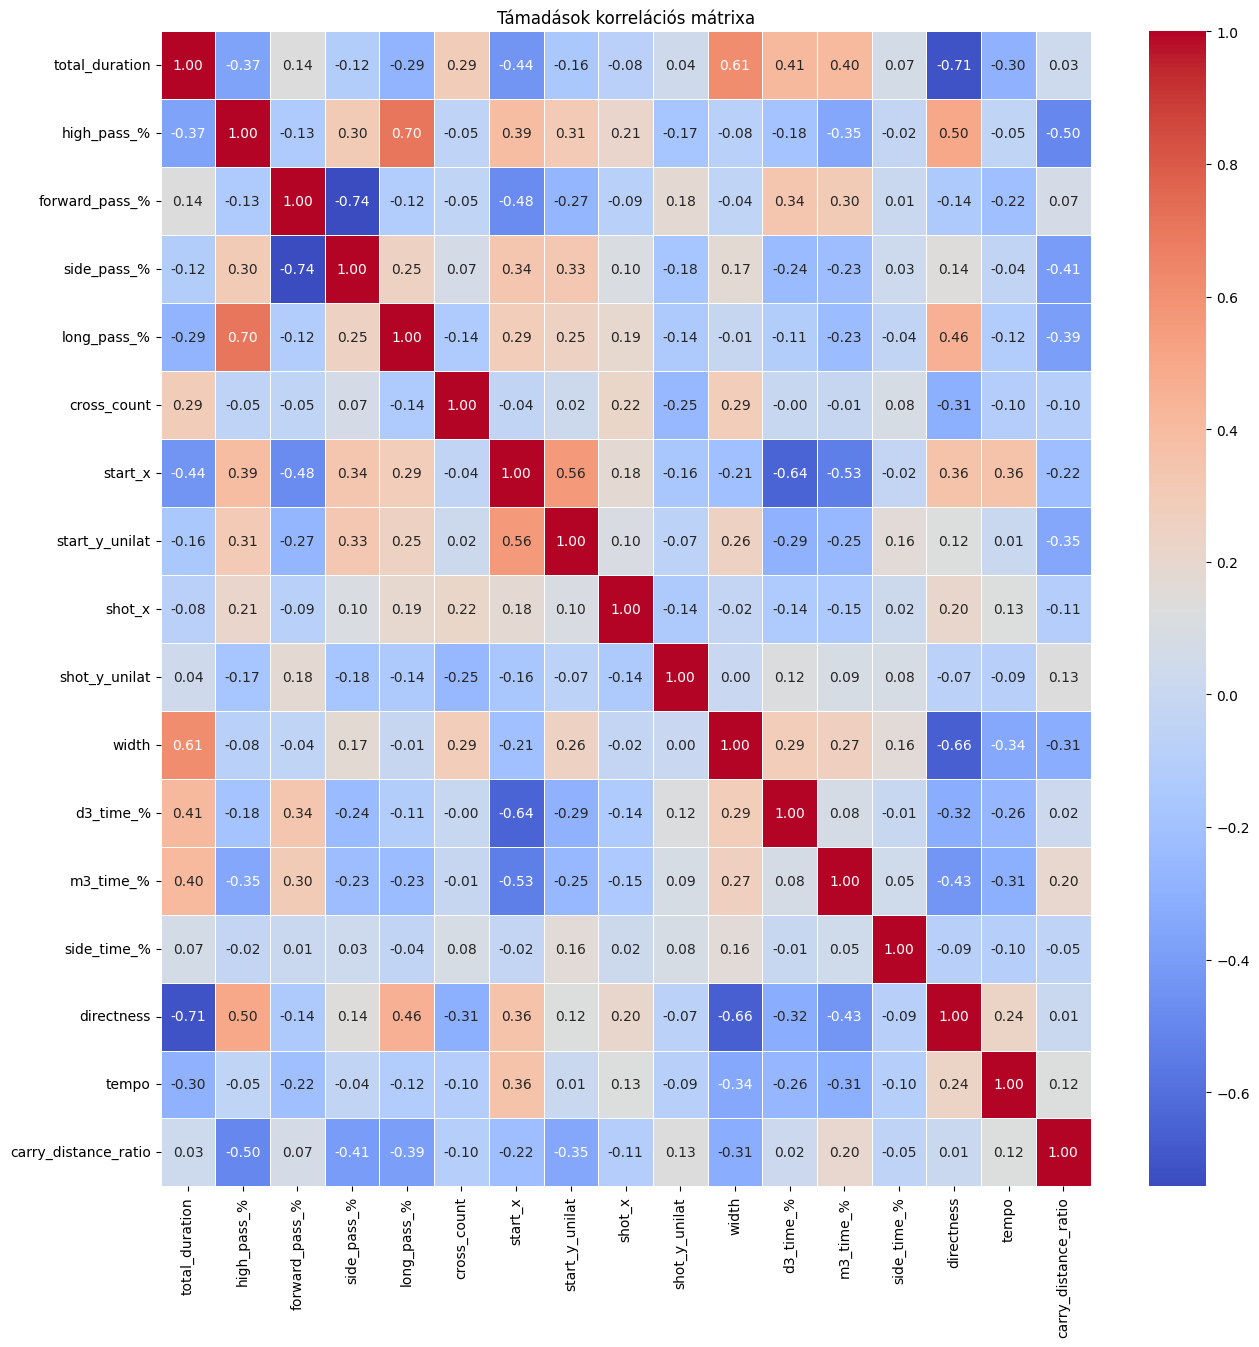

In [ ]:
# @title
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix=attacks_scaled_df.corr()

# Ábrázolás hőtérképpel
plt.figure(figsize=(15, 15))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Támadások korrelációs mátrixa")
plt.show()

## UMAP + HDBSCAN

In [ ]:

!pip install hdbscan


In [ ]:
import umap
import hdbscan
import matplotlib.pyplot as plt
import seaborn as sns

# 1. UMAP dimenziócsökkentés (a RobustScaler-rel skálázott adatokon)
# n_neighbors: 15-30 közötti érték javasolt (lokális vs. globális struktúra egyensúlya)
umap_reducer = umap.UMAP(
    n_neighbors=13,
    min_dist=0.0,      # Klaszterezéshez 0.0 a kötelező (szorosra húzza a pontokat)
    n_components=3,    # 2 dimenzió a könnyű vizualizációhoz és a HDBSCAN-hez
    random_state=42
)
attacks_umap = umap_reducer.fit_transform(attacks_scaled)




/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



In [ ]:
# 2. HDBSCAN klaszterezés a UMAP által transzformált téren
cluster_labels_final=clusterer = hdbscan.HDBSCAN(
    min_cluster_size=54,   # 2690 adatra kb. 1-2%
    min_samples=20,        # Finomhangolás a zajszűréshez
    metric='euclidean',
    cluster_selection_method='eom').fit_predict(attacks_umap)


counts = pd.Series(cluster_labels_final).value_counts().sort_index()

noise_count = counts.get(-1, 0)
noise_pct = (noise_count / len(cluster_labels_final)) * 100
print(f"Zaj (-1) elemszáma: {noise_count} ({noise_pct:.2f}%)")
for cluster_id, count in counts.items():
  name = "Zaj (-1)" if cluster_id == -1 else f"Klaszter {cluster_id}"
  print(f"  {name}: {count} db ({count / len(cluster_labels_final) * 100:.2f}%)")

Zaj (-1) elemszáma: 1731 (64.35%)
  Zaj (-1): 1731 db (64.35%)
  Klaszter 0: 54 db (2.01%)
  Klaszter 1: 384 db (14.28%)
  Klaszter 2: 366 db (13.61%)
  Klaszter 3: 155 db (5.76%)


In [ ]:
df_3d = pd.DataFrame(attacks_umap_3d, columns=['UMAP1', 'UMAP2', 'UMAP3'])
df_3d['cluster'] = cluster_labels.astype(str)

fig = px.scatter_3d(
    df_3d,
    x='UMAP1', y='UMAP2', z='UMAP3',
    color='cluster',
    title='3D UMAP Taktikai Klaszterek (Interaktív)',
    opacity=0.7
)
fig.update_traces(marker=dict(size=3))
fig.show()

ValueError: Shape of passed values is (2690, 4), indices imply (2690, 3)

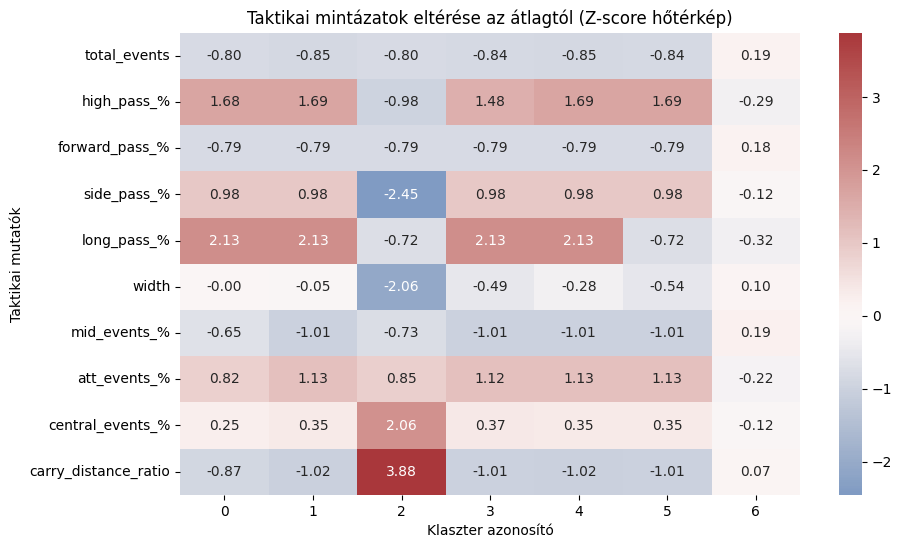

,total_events,high_pass_%,forward_pass_%,side_pass_%,long_pass_%,width,mid_events_%,att_events_%,central_events_%,carry_distance_ratio
cluster,,,,,,,,,,
-1,2.0,1.000000,0.0,1.000000,1.000000,41.20,0.0,1.000000,0.500000,0.000000
0,2.0,1.000000,0.0,1.000000,1.000000,46.65,0.0,1.000000,0.500000,0.000000
1,2.0,1.000000,0.0,1.000000,1.000000,43.70,0.0,1.000000,0.500000,0.000000
2,2.0,0.000000,0.0,0.000000,0.000000,2.40,0.0,1.000000,1.000000,1.000000
3,2.0,1.000000,0.0,1.000000,1.000000,36.05,0.0,1.000000,0.500000,0.000000
4,2.0,1.000000,0.0,1.000000,1.000000,39.40,0.0,1.000000,0.500000,0.000000
5,2.0,1.000000,0.0,1.000000,0.000000,33.40,0.0,1.000000,0.500000,0.000000
6,10.0,0.188345,0.2,0.666667,0.052632,46.40,0.3,0.533333,0.333333,0.202944


In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Címkék visszacsatolása az eredeti, skálázatlan adathalmazhoz
df_analysis = attacks_filtered.copy()
df_analysis['cluster'] = cluster_labels_final
#df_analysis['sequence_id'] = attacks['sequence_id']

# 2. Taktikai profilok létrehozása (medián kiszámítása klaszterenként)
cluster_profiles = df_analysis.groupby('cluster').median()


# 3. Z-score hőtérkép a globális átlagtól való eltérések szemléltetésére (zaj nélkül)
cluster_means = df_analysis[df_analysis['cluster'] != -1].groupby('cluster').mean()
global_mean = df_analysis.drop(columns=['cluster']).mean()
global_std = df_analysis.drop(columns=['cluster']).std()

z_scores = (cluster_means - global_mean) / global_std

plt.figure(figsize=(10, 6))
sns.heatmap(z_scores.T, cmap='vlag', annot=True, fmt=".2f", center=0)
plt.title('Taktikai mintázatok eltérése az átlagtól (Z-score hőtérkép)')
plt.xlabel('Klaszter azonosító')
plt.ylabel('Taktikai mutatók')
plt.show()
cluster_profiles

In [ ]:
import hdbscan
import umap
import pandas as pd

results = []

# Grid Search futtatása a UMAP és HDBSCAN paraméterekre
for n_neigh in [ 13, 27, 40, 54]:
    reducer = umap.UMAP(n_neighbors=n_neigh, min_dist=0.0, n_components=3, random_state=42)
    umap_emb = reducer.fit_transform(attacks_scaled)

    for mcs in [27, 40, 54, 67]:
        for ms in [13, 20, 27, 40]:
            clusterer = hdbscan.HDBSCAN(min_cluster_size=mcs, cluster_selection_method='eom', min_samples=ms, gen_min_span_tree=True)
            labels = clusterer.fit_predict(umap_emb)

            n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
            noise_pct = (labels == -1).sum() / len(labels) * 100

            # DBCV kiszámítása (ha legalább 2 klaszter keletkezett)
            dbcv_score = clusterer.relative_validity_ if n_clusters > 1 else -1

            results.append({
                'n_neighbors': n_neigh,
                'min_cluster_size': mcs,
                'min_samples': ms,
                'n_clusters': n_clusters,
                'noise_pct': round(noise_pct, 2),
                'DBCV': round(dbcv_score, 4)
            })

df_res = pd.DataFrame(results)

# Teljes eredménytábla megtekintése DBCV szerint rendezve (szűrés nélkül)


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:1952: UserWarning:

n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.



In [ ]:
print(df_res.sort_values(by='DBCV', ascending=False).head(30))

    n_neighbors  min_cluster_size  min_samples  n_clusters  noise_pct    DBCV
0            13                27           13           3       0.00  0.9002
4            13                40           13           3       0.00  0.9002
20           27                40           13           3       0.00  0.8975
16           27                27           13           3       0.00  0.8975
5            13                40           20           3       0.00  0.8908
1            13                27           20           3       0.00  0.8908
17           27                27           20           3       0.00  0.8868
21           27                40           20           3       0.00  0.8868
24           27                54           13           2       2.34  0.8746
28           27                67           13           2       2.34  0.8746
18           27                27           27           3       0.00  0.8690
22           27                40           27           3      

## PCA + KMeans

In [ ]:
!pip install factor_analyzer

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for factor_analyzer: filename=factor_analyzer-0.5.1-py2.py3-none-any.whl size=42656 sha256=bcb2745ac52460dd09dacd8e4a8f279d13a5ab420bcb597707baddc5e1491fb2
  Stored in directory: /root/.cache/pip/wheels/87/6e/8f/914f20e0242ee0214e5c8336031a2fab12e632e4695fbb7276
Successfully built factor_analyzer


In [ ]:
from factor_analyzer import calculate_bartlett_sphericity, calculate_kmo

# 1. Bartlett-teszt (p < 0.05 esetén a PCA módszertanilag megalapozott)
chi2, p_val = calculate_bartlett_sphericity(attacks_scaled)
print(f"Bartlett-teszt chi2: {chi2:.2f}, p-érték: {p_val:.5f}")

# 2. KMO-teszt (> 0.6 elfogadható mintavételi adekvátság)
kmo_vars, kmo_model = calculate_kmo(attacks_scaled)
print(f"KMO összegzett érték: {kmo_model:.4f}")

Bartlett-teszt chi2: 21786.20, p-érték: 0.00000
KMO összegzett érték: 0.6895


In [ ]:
import pandas as pd
import numpy as np
from sklearn.decomposition import PCA

# 1. PCA illesztése a skálázott adathalmazra
pca = PCA().fit(attacks_scaled)

# 2. Sajátértékek és variancia-mutatók kiszámítása
eigenvalues = pca.explained_variance_
var_ratio = pca.explained_variance_ratio_ * 100
cum_var = np.cumsum(var_ratio)

# 3. Összefoglaló DataFrame összeállítása és megjelenítése
pca_results_df = pd.DataFrame({
    'Főkomponens': [f'PC{i+1}' for i in range(len(eigenvalues))],
    'Sajátérték (Eigenvalue)': np.round(eigenvalues, 4),
    'Magyarázott variancia (%)': np.round(var_ratio, 2),
    'Kumulált variancia (%)': np.round(cum_var, 2)
})

print(pca_results_df.to_string(index=False))

Főkomponens  Sajátérték (Eigenvalue)  Magyarázott variancia (%)  Kumulált variancia (%)
        PC1                   2.5709                      26.36                   26.36
        PC2                   1.9837                      20.34                   46.70
        PC3                   1.0653                      10.92                   57.62
        PC4                   0.8423                       8.64                   66.25
        PC5                   0.5601                       5.74                   71.99
        PC6                   0.5236                       5.37                   77.36
        PC7                   0.4418                       4.53                   81.89
        PC8                   0.3975                       4.08                   85.97
        PC9                   0.3094                       3.17                   89.14
       PC10                   0.2657                       2.72                   91.86
       PC11                   0.